# 008 Dropout：题目要求

**需要完成：** 实现 inverted dropout 的训练/推理和反向；验证均值、置零比例与梯度；接入多层网络；完成 500 张图、25 轮的有/无 dropout 对照并解释结果。

**实验范围与验收：** 本实现 p 为保留概率；dropout=0 表示关闭。所有对照均保留真实结果。

**阅读顺序：** 先阅读原题和代码块前的中文解析，再检查实际输出与问题记录；若本题包含方法二，它紧随对应方法一，使用独立状态。方法一不得依赖方法二才能运行。

**课程参考：** [CS231n 课程资料](https://cs231n.github.io/)。本题的实现、检查和实验结果按下文顺序记录。

## 读代码前先看模型：随机失活

本实现的 p 是保留概率。训练时随机屏蔽一部分隐藏单元，推理时直接使用完整激活。

![随机失活的数据流](../assets/model_flow/008_Dropout.svg)

**从定义推到实现。**

$$
m\sim\mathrm{Bernoulli}(p),\quad y=xm/p,\quad E[y\mid x]=x
$$

因为 E[m]=p，除以 p 后均值保持不变。给定本次抽到的掩码，导数是 m/p，故 dx=dy·m/p。反向重新抽掩码会让梯度对应另一条前向路径。

**库在这里解决什么问题？** NumPy 随机数产生掩码；梯度检查固定随机种子，让加 h 和减 h 的两次前向使用相同掩码。

| 本题导入的模块 | 在这份实验中的用途 |
|---|---|
| `__future__` | 声明历史 Python 兼容语义。 |
| `cs231n.classifiers.fc_net` | 加载当前作业的本地实现。模型代码负责计算预测或损失，notebook 用真实输入检查和训练。 |
| `cs231n.data_utils` | 处理该作业的数据、特征或显示输入，使主实验能直接使用约定的数组格式。 |
| `cs231n.gradient_check` | 用中心差分近似导数，独立核对手写反向传播。 |
| `cs231n.solver` | 负责批次抽样、训练循环和参数更新，使模型的 loss 方法只处理一次计算。 |
| `matplotlib.pyplot` | 把像素、损失或准确率转换为可读图像，绘图单元只读取已有结果。 |
| `numpy` | 把一批样本作为数组处理。矩阵乘法合并样本计算，广播让偏置或均值沿样本轴复用。 |
| `os` | 读取运行环境或处理路径，连接实验代码和本机文件系统。 |
| `pathlib` | 构造数据与结果的文件路径，使当前作业从约定目录读取资源。 |
| `random` | 控制 Python 自己的随机抽样，例如图像平移。它与 NumPy、PyTorch 的随机状态分别管理。 |
| `study_runtime` | 解析共享数据路径、读取本机资源或保存本题结果，避免各题重复创建数据副本。 |
| `sys` | 设置本作业的模块搜索路径，使同名 cs231n 包来自当前 assignment。 |
| `threadpoolctl` | 限制数值库的并行线程，避免小矩阵运算把更多时间花在线程调度上。 |
| `time` | 测量代码开始与结束的实际时间，在相同输入上比较实现成本。 |

**用一个小例子检查理解。** 若输入为 4、保留概率为 0.5，则训练输出以相等概率取 0 或 8，期望仍为 4。推理时直接使用 4；把训练输出再乘 0.5 会重复缩放。

## 读论文图：究竟丢掉了什么？缩放在哪一步？

![Dropout 论文图 1](../assets/paper_figures/Dropout_Fig1.png)

Srivastava 等，*Dropout: A Simple Way to Prevent Neural Networks from Overfitting*，JMLR 2014，图 1，期刊页 1930。[查看论文原页](https://jmlr.org/papers/volume15/srivastava14a/srivastava14a.pdf#page=2)

左侧是完整网络，右侧是一次抽样得到的子网络。叉号表示本次计算屏蔽这个单元，相连路径也暂时失效。下一批可以抽到另一组掩码；权重仍在这些子网络间共享，叉号并不是永久剪枝。

![Dropout 论文图 2](../assets/paper_figures/Dropout_Fig2.png)

同文图 2，期刊页 1931。[查看论文原页](https://jmlr.org/papers/volume15/srivastava14a/srivastava14a.pdf#page=3)

论文图 2 的写法是训练时以概率 p 使用权重 w，推理时常开并使用 pw。本题将缩放移到训练阶段：保留值除以 p，推理时原样传递。输入为 4、p=0.5 时，本题训练输出为 0 或 8，期望仍是 4。因此不能在测试时再乘一次 p。

反向读取前向实际保存的 mask，执行 dout×mask。有限差分时固定掩码，使正负扰动作用在同一子网络上；正式训练则要让掩码随批次变化。

# 随机失活
Dropout[1]是一种神经网络正则化的技术，它通过在前向传递中将一些特征随机设置为0来实现。在这个练习中，您将实现一个dropout层，并修改您的全连接网络，以选择使用dropout。

[1] Geoffrey E. Hinton 等人,"通过防止特征探测器的共同适应来改进神经网络",arXiv 2012

**本段解析**

固定 NumPy 与 Python 随机种子为 231，读取共享数据配置，并限制 BLAS 线程数量。这样既能运行验证初始化和抽样，也能避免小矩阵运算中线程调度开销；原始数据文件保持不变。

**第 1 块：顺着变量读**

本块实际导入：`os`、`sys`、`random`、`pathlib.Path`、`study_runtime.data_path`、`numpy`、`threadpoolctl.threadpool_limits`。各模块在本题中的职责见开头的库说明。

In [1]:
# 固定实验起点；读取共享数据路径；限制 BLAS 线程，避免多线程调度开销。
import os, sys, random
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from study_runtime import data_path
import numpy as np
from threadpoolctl import threadpool_limits
_blas_limit = threadpool_limits(limits=4)
np.random.seed(231)
random.seed(231)


**第 2 块｜准备掩码与网络**

导入 inverted dropout 算子和带 dropout 的全连接模型。当前代码的 p 表示保留概率；构造参数 dropout=0 表示关闭功能，不能把它误解为保留零个神经元。

此处定义 `rel_error(x, y)`。函数体在调用时执行。

本块实际导入：`__future__.print_function`、`time`、`numpy`、`matplotlib.pyplot`、`cs231n.classifiers.fc_net.*`、`cs231n.data_utils.get_CIFAR10_data`、`cs231n.gradient_check.eval_numerical_gradient`、`cs231n.gradient_check.eval_numerical_gradient_array`、`cs231n.solver.Solver`。各模块在本题中的职责见开头的库说明。

本块产出的变量接着用于：`rel_error` → 第 5 块。

In [2]:
# 跟往常一样,有点陷害
from __future__ import print_function
import time
import numpy as np
import matplotlib.pyplot as plt
from cs231n.classifiers.fc_net import *
from cs231n.data_utils import get_CIFAR10_data
from cs231n.gradient_check import eval_numerical_gradient, eval_numerical_gradient_array
from cs231n.solver import Solver

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # 设置地块的默认大小
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

# 用于自动重新装入外部模块
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
%load_ext autoreload
%autoreload 2

def rel_error(x, y):
  """逐元素计算 |x−y| / max(1e−8, |x|+|y|)，返回其中最大值。分母很小时还应查看绝对误差。"""
  return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

**第 3 块｜读取固定划分**

加载固定 CIFAR-10 划分，并检查图像与标签形状。后面的正则化对照只取训练部分的 500 张图，验证划分仍保持独立。

本块产出的变量接着用于：`data` → 第 7 块。

In [3]:
# 装入(预处理的)CIFAR10数据.

data = get_CIFAR10_data()
for k, v in data.items():
  print('%s: ' % k, v.shape)

X_train:  (49000, 3, 32, 32)
y_train:  (49000,)
X_val:  (1000, 3, 32, 32)
y_val:  (1000,)
X_test:  (1000, 3, 32, 32)
y_test:  (1000,)


# 退学证书
在文件`cs231n/layers.py`，为dropout执行向前传递。由于dropout在训练和测试期间的行为不同，请确保实现两种模式的操作。
完成之后，运行下面的单元以测试您的实现。

**第 4 块｜检查保留概率与均值**

对均值约为 10 的输入，以多个保留概率生成 Bernoulli 掩码，并把保留值除以 p。检查训练输出均值与原输入接近、置零比例约为 1−p；test 模式直接返回输入，不再缩放。



In [4]:
np.random.seed(231)
x = np.random.randn(500, 500) + 10

for p in [0.3, 0.6, 0.75]:
  out, _ = dropout_forward(x, {'mode': 'train', 'p': p})
  out_test, _ = dropout_forward(x, {'mode': 'test', 'p': p})

  print('Running tests with p = ', p)
  print('Mean of input: ', x.mean())
  print('Mean of train-time output: ', out.mean())
  print('Mean of test-time output: ', out_test.mean())
  print('Fraction of train-time output set to zero: ', (out == 0).mean())
  print('Fraction of test-time output set to zero: ', (out_test == 0).mean())
  print()

Running tests with p =  0.3
Mean of input:  10.000207878477502
Mean of train-time output:  10.035072797050494
Mean of test-time output:  10.000207878477502
Fraction of train-time output set to zero:  0.699124
Fraction of test-time output set to zero:  0.0

Running tests with p =  0.6
Mean of input:  10.000207878477502
Mean of train-time output:  9.976910758765856
Mean of test-time output:  10.000207878477502
Fraction of train-time output set to zero:  0.401368
Fraction of test-time output set to zero:  0.0

Running tests with p =  0.75
Mean of input:  10.000207878477502
Mean of train-time output:  9.993068588261146
Mean of test-time output:  10.000207878477502
Fraction of train-time output set to zero:  0.250496
Fraction of test-time output set to zero:  0.0



# 辍学后通过
在文件`cs231n/layers.py`，实现dropout的向后传递。这样做之后，运行以下单元格来进行数值梯度检查。

**第 5 块｜固定掩码比较输入梯度**

固定随机种子使每次有限差分使用相同掩码，再对比解析反向 dout·mask 与数值梯度。如果扰动前后重新随机采样掩码，数值差分测到的就不只是输入扰动。

前序输入：`rel_error` 来自第 2 块。

In [5]:
np.random.seed(231)
x = np.random.randn(10, 10) + 10
dout = np.random.randn(*x.shape)

dropout_param = {'mode': 'train', 'p': 0.8, 'seed': 123}
out, cache = dropout_forward(x, dropout_param)
dx = dropout_backward(dout, cache)
dx_num = eval_numerical_gradient_array(lambda xx: dropout_forward(xx, dropout_param)[0], x, dout)

print('dx relative error: ', rel_error(dx, dx_num))

dx relative error:  5.445612718272284e-11


# 与辍学者完全连接的蚊帐
在文件`cs231n/classifiers/fc_net`中。修改您的实现以使用dropout。从表面上看，如果网络的构造函数为“dropout”参数接收到一个非零值，那么网络应该在每个ReLU非线性之后立即添加dropout。这样做之后，运行下面的代码来对实现进行数值梯度检查。

**第 6 块｜验证完整网络的掩码反向**

在多个 dropout 参数下检查完整网络各参数梯度，包含关闭 dropout 和全部保留的边界。模型中的掩码位于 ReLU 后，反向先过 dropout 再过 ReLU，顺序不能颠倒。

- `np.random.randint(C, size=(N,))`：从给定整数范围抽样，结果用作索引或离散标签。

前序输入：`rel_error` 来自第 2 块。

In [6]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for dropout in [0, 0.25, 0.5, 0.75, 1]:
  print('Running check with dropout = ', dropout)
  model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                            weight_scale=5e-2, dtype=np.float64,
                            dropout=dropout, seed=123)
  loss, grads = model.loss(X, y)
  
  print('Initial loss: ', loss)

  for name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
    print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))
  print()

Running check with dropout =  0
Initial loss:  2.3004790897684924
W1 relative error: 1.48e-07


W2 relative error: 2.21e-05


W3 relative error: 3.53e-07
b1 relative error: 5.38e-09
b2 relative error: 2.09e-09
b3 relative error: 5.80e-11

Running check with dropout =  0.25
Initial loss:  2.2924325088330475
W1 relative error: 2.74e-08


W2 relative error: 2.98e-09


W3 relative error: 4.29e-09
b1 relative error: 7.78e-10
b2 relative error: 3.36e-10
b3 relative error: 1.65e-10

Running check with dropout =  0.5
Initial loss:  2.3042759220785896
W1 relative error: 3.11e-07


W2 relative error: 1.84e-08


W3 relative error: 5.35e-08


b1 relative error: 5.37e-09
b2 relative error: 2.99e-09
b3 relative error: 1.13e-10

Running check with dropout =  0.75
Initial loss:  2.302848733153321
W1 relative error: 7.87e-07
W2 relative error: 1.45e-07
W3 relative error: 1.70e-07
b1 relative error: 1.83e-08
b2 relative error: 2.81e-09
b3 relative error: 1.49e-10

Running check with dropout =  1
Initial loss:  2.30485979047391


W1 relative error: 8.77e-07
W2 relative error: 3.64e-07
W3 relative error: 6.33e-08
b1 relative error: 1.22e-07
b2 relative error: 4.50e-09
b3 relative error: 1.15e-10



# 正则化实验
作为一个实验，我们将在500个训练示例上训练网络,然后，我们将在一段时间内可视化这几个网络的训练和验证准确性。

**第 7 块｜训练有无失活的网络**

使用相同 500 张训练图，分别训练关闭 dropout 与保留概率 0.75 的单隐藏层网络，共 25 轮。两组都有独立模型与 Adam 状态，输出 Solver 历史用于观察正则化影响。

前序输入：`data` 来自第 3 块。

本块产出的变量接着用于：`dropout_choices` → 第 8 块，`solvers` → 第 8 块。

In [7]:
# 训练两只相同的网,一个有退学,一个没有
np.random.seed(231)
num_train = 500
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

solvers = {}
dropout_choices = [0, 0.75]
for dropout in dropout_choices:
  model = FullyConnectedNet([500], dropout=dropout)
  print(dropout)

  solver = Solver(model, small_data,
                  num_epochs=25, batch_size=100,
                  update_rule='adam',
                  optim_config={
                    'learning_rate': 5e-4,
                  },
                  verbose=True, print_every=100)
  solver.train()
  solvers[dropout] = solver

0


(Iteration 1 / 125) loss: 7.856643
(Epoch 0 / 25) train acc: 0.260000; val_acc: 0.184000
(Epoch 1 / 25) train acc: 0.416000; val_acc: 0.258000


(Epoch 2 / 25) train acc: 0.482000; val_acc: 0.276000
(Epoch 3 / 25) train acc: 0.532000; val_acc: 0.277000


(Epoch 4 / 25) train acc: 0.600000; val_acc: 0.271000
(Epoch 5 / 25) train acc: 0.708000; val_acc: 0.299000


(Epoch 6 / 25) train acc: 0.722000; val_acc: 0.282000
(Epoch 7 / 25) train acc: 0.832000; val_acc: 0.255000


(Epoch 8 / 25) train acc: 0.878000; val_acc: 0.269000
(Epoch 9 / 25) train acc: 0.902000; val_acc: 0.275000


... (30 outputs left out)

(Epoch 22 / 25) train acc: 0.974000; val_acc: 0.303000


(Epoch 23 / 25) train acc: 0.976000; val_acc: 0.314000


(Epoch 24 / 25) train acc: 0.980000; val_acc: 0.303000


(Epoch 25 / 25) train acc: 0.950000; val_acc: 0.296000


**第 8 块｜比较两条泛化曲线**

绘制两组训练、验证准确率曲线。dropout 通常降低记忆训练集的速度，但是否改善验证表现需由本次数据判断；原标签中的 dropout 数值在此实现中实际代表保留概率。

前序输入：`dropout_choices` 来自第 7 块，`solvers` 来自第 7 块。

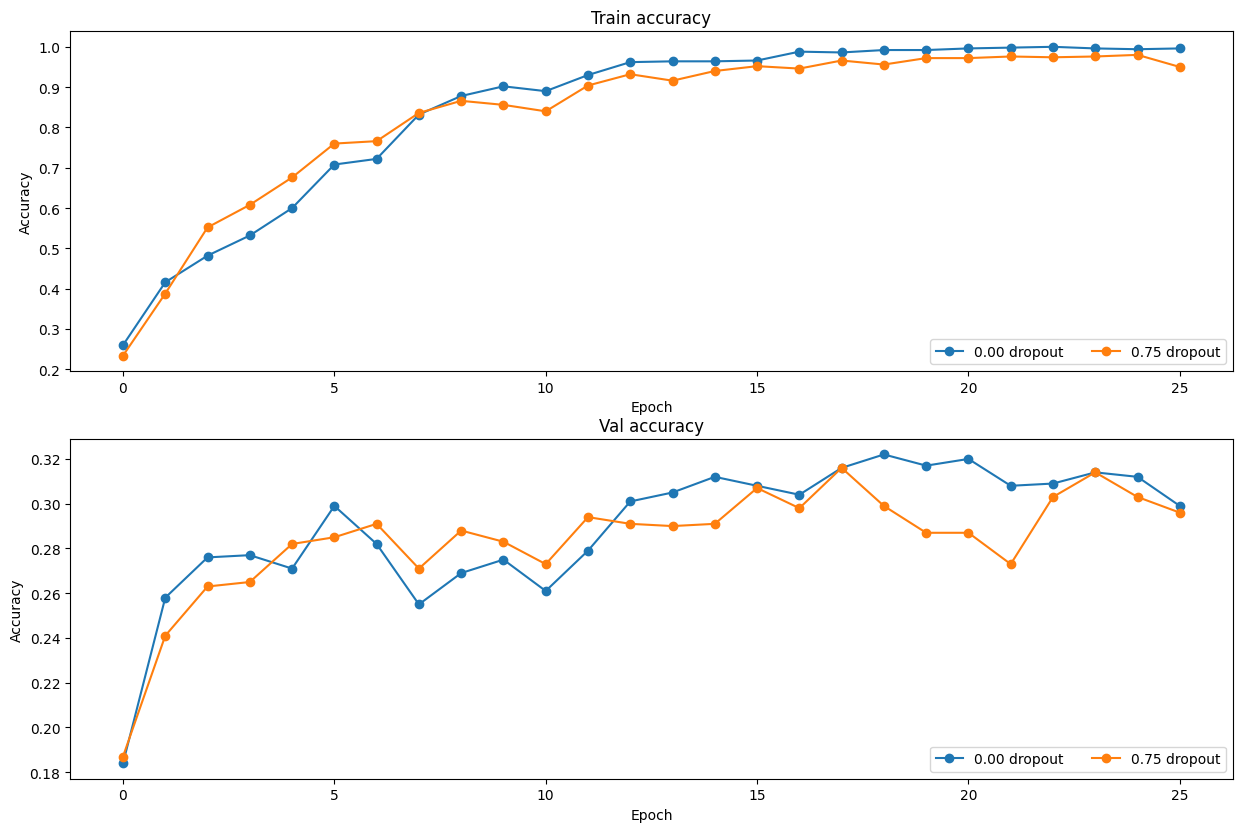

In [8]:
# 两种模型的绘图列车和验证精度

train_accs = []
val_accs = []
for dropout in dropout_choices:
  solver = solvers[dropout]
  train_accs.append(solver.train_acc_history[-1])
  val_accs.append(solver.val_acc_history[-1])

plt.subplot(3, 1, 1)
for dropout in dropout_choices:
  plt.plot(solvers[dropout].train_acc_history, '-o', label='%.2f dropout' % dropout)
plt.title('Train accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(ncol=2, loc='lower right')
  
plt.subplot(3, 1, 2)
for dropout in dropout_choices:
  plt.plot(solvers[dropout].val_acc_history, '-o', label='%.2f dropout' % dropout)
plt.title('Val accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(ncol=2, loc='lower right')

plt.gcf().set_size_inches(15, 15)
plt.show()

# 问题
解释你在这个实验中看到的。这说明了什么?

# 我的分析

两组模型都在 500 张训练图上明显过拟合。加入保留概率 0.75 的 dropout 后，部分训练阶段的拟合速度和训练准确率受到抑制，但验证曲线仍有波动，不能据此声称完全消除了过拟合。它是随机子网络形式的正则化；保留概率、训练时间和模型容量需要共同选择。本实现中的 0.75 是保留比例，不是丢弃 75%。

### 保存本次实验
输入是上面实际训练得到的模型、指标和曲线。只保存模型参数与实验结果，不复制原始数据；输出写入本题独立目录，供运行验证核对。

**第 9 块：顺着变量读**

本块实际导入：`study_runtime.save_experiment`。各模块在本题中的职责见开头的库说明。

In [9]:
from study_runtime import save_experiment
experiment_metrics = save_experiment(globals(), '008_Dropout')


本机实验指标： {}


## 实践补充：问题、检查与方法选择

**语义核对。** 本实现 p 是保留概率；部分旧注释的丢弃概率措辞不准确。数值梯度时固定掩码，真实训练不应每批重置到完全相同的掩码。

**本次观察。** 两组模型均在 500 张图上过拟合；dropout 改变训练和验证轨迹，但没有消除全部泛化问题。

**方法选择。** 本题目的是理解随机失活的前后向，添加更多正则器会改变实验因素。更充分的泛化优化放在后面的独立分类扩展中比较。

更完整的故障证据见 [问题与解决记录](../003_问题与解决记录.md)。